<a href="https://colab.research.google.com/github/njalagam23/neural-networks-from-scratch/blob/main/day02_gradient_descent_backprop_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

rng = np.random.default_rng(42)

# Generate 400 synthetic customers
n = 400

usage = rng.uniform(0, 40, n)
tenure = rng.integers(1, 61, n)
tickets = rng.poisson(1.5, n)

X = np.column_stack([usage, tenure, tickets])

# Simulated churn outcomes
logits = 0.9 - 0.14 * usage - 0.035 * tenure + 0.9 * tickets
true_probs = 1 / (1 + np.exp(-logits))

y = (rng.random(n) < true_probs).astype(float).reshape(-1, 1)

# Train/test split
idx = rng.permutation(n)
train_idx, test_idx = idx[:320], idx[320:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Standardize using training statistics only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (320, 3)
Testing: (80, 3)


In [2]:
# Initialize weights
W1 = rng.normal(0, 0.1, (3, 8))
b1 = np.zeros((1, 8))

W2 = rng.normal(0, 0.1, (8, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    hidden = np.maximum(0, z1)

    z2 = hidden @ W2 + b2
    predictions = 1 / (1 + np.exp(-np.clip(z2, -30, 30)))

    return z1, hidden, predictions

In [3]:
def binary_cross_entropy(predictions, actual):
    predictions = np.clip(predictions, 1e-8, 1 - 1e-8)

    loss = -np.mean(
        actual * np.log(predictions)
        + (1 - actual) * np.log(1 - predictions)
    )

    return loss

z1, hidden, predictions = forward(X_train)

initial_loss = binary_cross_entropy(predictions, y_train)

print("Initial loss:", initial_loss)

Initial loss: 0.6933185097798515


In [4]:
learning_rate = 0.2
epochs = 600

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    z1, hidden, predictions = forward(X_train)

    loss = binary_cross_entropy(predictions, y_train)
    loss_history.append(loss)

    # Backpropagation
    m = len(X_train)

    dz2 = (predictions - y_train) / m

    dW2 = hidden.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    dhidden = dz2 @ W2.T
    dz1 = dhidden * (z1 > 0)

    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # Gradient descent
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

Epoch 100, Loss: 0.3633
Epoch 200, Loss: 0.3428
Epoch 300, Loss: 0.3374
Epoch 400, Loss: 0.3339
Epoch 500, Loss: 0.3320
Epoch 600, Loss: 0.3286


In [5]:
_, _, test_predictions = forward(X_test)

predicted_labels = (test_predictions >= 0.5).astype(int)

accuracy = np.mean(predicted_labels == y_test)

print("Test accuracy:", accuracy)

Test accuracy: 0.825


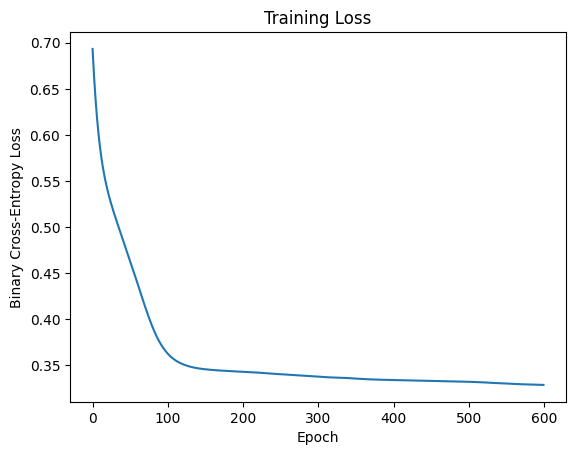

In [6]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss")
plt.show()

In [7]:
assert X_train.shape == (320, 3)
assert W1.shape == (3, 8)
assert W2.shape == (8, 1)
assert test_predictions.shape == (80, 1)

assert np.isfinite(loss_history).all()
assert loss_history[-1] < initial_loss

print("Core checks passed!")

Core checks passed!
